In [1]:
%load_ext autoreload

In [2]:
import pandas as pd
from ast import literal_eval
import protfasta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob, os
from tqdm import tqdm
import ipyparallel as ipp

%aimport ADpred_LambertTFs_helper

# Combining my predictions with Claire's from "Collecting Claire predictions...".ipynb

In [3]:
train_with_cl_preds = pd.read_csv("../data/train_seqs_with_test_overlap_removed_with_cl_preds.csv", index_col = 0)
train_with_cl_preds

,id,seq,CL_adpred_preds,CL_adhunter_centers,CL_adhunter_preds,CL_paddle_centers,CL_paddle_preds,CL_tada_centers,CL_tada_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1..."
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0...."
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.44014657,0.43404478,0.4288694,0...."
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...,"[5.1246793e-06,4.114612e-06,3.4057525e-06,2.67...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21081.258,20210.355,21164.363,27481.016,34338...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.9605311,0.9986002,1.0397161,1.0758569,1.092...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.14767295,0.15255511,0.16043384,0.16341466,0..."


In [4]:
train_with_cl_sk_preds = train_with_cl_preds

In [5]:
# Adding my ADPpred predictions

sk_ADpred_pred_paths = glob.glob("/global/scratch/projects/fc_mvslab/OpenProjects/Sanjana/consensus_AD_predictor/output/train_seqs_with_test_overlap_removed_sk_only/*ADpred*preds*")
print(len(sk_ADpred_pred_paths))

sk_ADpred_preds = []
for path in tqdm(sk_ADpred_pred_paths):
    for chunk in pd.read_csv(path, index_col=0, chunksize=1000):  # read in chunks
        sk_ADpred_preds.append(chunk)
        
sk_ADpred_preds = pd.concat(sk_ADpred_preds)
sk_ADpred_preds = sk_ADpred_preds.rename(columns = {"name" : "id", 
                                                    "sequence" : "seq",
                                                   "adpred_preds" : "SK_adpred_preds"})
sk_ADpred_preds = sk_ADpred_preds.drop_duplicates(subset = ["id", "seq"])

train_with_cl_sk_preds = pd.merge(train_with_cl_sk_preds, sk_ADpred_preds, how = 'left')
train_with_cl_sk_preds

142


100%|██████████| 142/142 [00:12<00:00, 11.07it/s]


,id,seq,CL_adpred_preds,CL_adhunter_centers,CL_adhunter_preds,CL_paddle_centers,CL_paddle_preds,CL_tada_centers,CL_tada_preds,SK_adpred_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.014501843,0.017827885,0.00781931,0.01072559..."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.0001438626,0.00035412342,0.0003735048,0.000..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.004338817,0.0073712594,0.008403782,0.016222..."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6..."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.00013295647,0.0001215624,0.00011178966,0.00..."
...,...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1...",NaN
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0....",NaN
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.44014657,0.43404478,0.4288694,0....",NaN
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...,"[5.1246793e-06,4.114612e-06,3.4057525e-06,2.67...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21081.258,20210.355,21164.363,27481.016,34338...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.9605311,0.9986002,1.0397161,1.0758569,1.092...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.14767295,0.15255511,0.16043384,0.16341466,0...",NaN


In [6]:
# Adding ADHunter predictions

sk_ADHunter_pred_paths = glob.glob("/global/scratch/projects/fc_mvslab/OpenProjects/Sanjana/consensus_AD_predictor/output/train_seqs_with_test_overlap_removed_sk_only/*ADHunter*preds*")
print(len(sk_ADHunter_pred_paths))

sk_ADHunter_preds = []
for path in tqdm(sk_ADHunter_pred_paths):
    for chunk in pd.read_csv(path, chunksize=1000):  # read in chunks
        sk_ADHunter_preds.append(chunk)
    
sk_ADHunter_preds = pd.concat(sk_ADHunter_preds)
sk_ADHunter_preds = sk_ADHunter_preds.rename(columns = {"name" : "id", 
                                                    "sequence" : "seq",
                                                        "adhunter_centers" : "SK_adhunter_centers",
                                                   "adhunter_preds" : "SK_adhunter_preds"})
sk_ADHunter_preds = sk_ADHunter_preds.drop_duplicates(subset = ["id", "seq"])
train_with_cl_sk_preds = pd.merge(train_with_cl_sk_preds, sk_ADHunter_preds, how = 'left')
train_with_cl_sk_preds

139


100%|██████████| 139/139 [00:12<00:00, 10.80it/s]


,id,seq,CL_adpred_preds,CL_adhunter_centers,CL_adhunter_preds,CL_paddle_centers,CL_paddle_preds,CL_tada_centers,CL_tada_preds,SK_adpred_preds,Unnamed: 0,SK_adhunter_centers,SK_adhunter_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.014501843,0.017827885,0.00781931,0.01072559...",0.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40465.336,39714.215,36622.324,39168.64,34978...."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.0001438626,0.00035412342,0.0003735048,0.000...",1.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[32509.066,30355.93,28649.129,25147.93,20923.0..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.004338817,0.0073712594,0.008403782,0.016222...",2.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[29600.562,27908.555,23943.48,22679.992,21695...."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6...",3.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24640.102,24443.316,23884.91,23502.457,33014...."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.00013295647,0.0001215624,0.00011178966,0.00...",4.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[16339.532,15863.892,15742.899,16619.082,16961..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1...",NaN,NaN,NaN,NaN
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0....",NaN,NaN,NaN,NaN
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.44014657,0.43404478,0.4288694,0....",NaN,NaN,NaN,NaN
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...,"[5.1246793e-06,4.114612e-06,3.4057525e-06,2.67...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21081.258,20210.355,21164.363,27481.016,34338...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.9605311,0.9986002,1.0397161,1.0758569,1.092...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.14767295,0.15255511,0.16043384,0.16341466,0...",NaN,NaN,NaN,NaN


In [7]:
# Adding PADDLE predictions

sk_Paddle_pred_paths = glob.glob("/global/scratch/projects/fc_mvslab/OpenProjects/Sanjana/consensus_AD_predictor/output/train_seqs_with_test_overlap_removed_sk_only/*Paddle*preds*")

sk_Paddle_preds = []
for path in tqdm(sk_Paddle_pred_paths):
    for chunk in pd.read_csv(path, chunksize=1000, index_col = 0):  # read in chunks
        sk_Paddle_preds.append(chunk)
    
sk_Paddle_preds = pd.concat(sk_Paddle_preds)
sk_Paddle_preds = sk_Paddle_preds.rename(columns = {"name" : "id", 
                                                    "sequence" : "seq",
                                                        "paddle_centers" : "SK_paddle_centers",
                                                   "paddle_preds" : "SK_paddle_preds"})
sk_Paddle_preds = sk_Paddle_preds.drop_duplicates(subset = ["id", "seq"])
train_with_cl_sk_preds = pd.merge(train_with_cl_sk_preds, sk_Paddle_preds, how = 'left')
train_with_cl_sk_preds

100%|██████████| 142/142 [00:15<00:00,  9.08it/s]


,id,seq,CL_adpred_preds,CL_adhunter_centers,CL_adhunter_preds,CL_paddle_centers,CL_paddle_preds,CL_tada_centers,CL_tada_preds,SK_adpred_preds,Unnamed: 0,SK_adhunter_centers,SK_adhunter_preds,SK_paddle_centers,SK_paddle_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.014501843,0.017827885,0.00781931,0.01072559...",0.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40465.336,39714.215,36622.324,39168.64,34978....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.017282724,-0.017990192,-0.021199908,-0.021..."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.0001438626,0.00035412342,0.0003735048,0.000...",1.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[32509.066,30355.93,28649.129,25147.93,20923.0...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.31806868,0.28675005,0.27596197,0.25877306,0..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.004338817,0.0073712594,0.008403782,0.016222...",2.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[29600.562,27908.555,23943.48,22679.992,21695....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.24082585,0.21805342,0.19448315,0.16699585,0..."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6...",3.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24640.102,24443.316,23884.91,23502.457,33014....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.418225,0.4298997,0.441755,0.44852835,0.4521..."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.00013295647,0.0001215624,0.00011178966,0.00...",4.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[16339.532,15863.892,15742.899,16619.082,16961...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.22651581,0.23068734,0.2278125,0.23869318,0...."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1...",NaN,NaN,NaN,NaN,NaN,NaN
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0....",NaN,NaN,NaN,NaN,NaN,NaN
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.44014657,0.43404478,0.4288694,0....",NaN,NaN,NaN,NaN,NaN,NaN
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...,"[5.1246793e-06,4.114612e-06,3.4057525e-06,2.67...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21081.258,20210.355,21164.363,27481.016,34338...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.9605311,0.9986002,1.0397161,1.0758569,1.092...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.14767295,0.15255511,0.16043384,0.16341466,0...",Na

In [8]:
# Adding TADA predictions

sk_TADA_pred_paths = glob.glob("/global/scratch/projects/fc_mvslab/OpenProjects/Sanjana/consensus_AD_predictor/output/train_seqs_with_test_overlap_removed_sk_only/*TADA*preds*")

sk_TADA_preds = []
for path in tqdm(sk_TADA_pred_paths):
    for chunk in pd.read_csv(path, chunksize=1000):  # read in chunks
        sk_TADA_preds.append(chunk)
        
sk_TADA_preds = pd.concat(sk_TADA_preds)
sk_TADA_preds = sk_TADA_preds.rename(columns = {"name" : "id", 
                                                    "sequence" : "seq",
                                                        "tada_centers" : "SK_tada_centers",
                                                   "tada_preds" : "SK_tada_preds"})
sk_TADA_preds = sk_TADA_preds.drop_duplicates(subset = ["id", "seq"])

train_with_cl_sk_preds = pd.merge(train_with_cl_sk_preds, sk_TADA_preds, how = 'left')
train_with_cl_sk_preds

100%|██████████| 139/139 [00:14<00:00,  9.72it/s]


,id,seq,CL_adpred_preds,CL_adhunter_centers,CL_adhunter_preds,CL_paddle_centers,CL_paddle_preds,CL_tada_centers,CL_tada_preds,SK_adpred_preds,Unnamed: 0,SK_adhunter_centers,SK_adhunter_preds,SK_paddle_centers,SK_paddle_preds,SK_tada_centers,SK_tada_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.014501843,0.017827885,0.00781931,0.01072559...",0.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40465.336,39714.215,36622.324,39168.64,34978....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.017282724,-0.017990192,-0.021199908,-0.021...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1825367,0.18771008,0.1811311,0.16013218,0.1..."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.0001438626,0.00035412342,0.0003735048,0.000...",1.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[32509.066,30355.93,28649.129,25147.93,20923.0...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.31806868,0.28675005,0.27596197,0.25877306,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1996398,0.1909486,0.19241591,0.19613661,0.1..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.004338817,0.0073712594,0.008403782,0.016222...",2.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[29600.562,27908.555,23943.48,22679.992,21695....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.24082585,0.21805342,0.19448315,0.16699585,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.20011021,0.18792471,0.17850415,0.17156768,0..."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6...",3.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24640.102,24443.316,23884.91,23502.457,33014....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.418225,0.4298997,0.441755,0.44852835,0.4521...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16546656,0.16327353,0.16205797,0.16644616,0..."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.00013295647,0.0001215624,0.00011178966,0.00...",4.0,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[16339.532,15863.892,15742.899,16619.082,16961...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.22651581,0.23068734,0.2278125,0.23869318,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16999598,0.16993652,0.16276489,0.159435,0.1..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0....",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,

In [9]:
train_with_cl_sk_preds = train_with_cl_sk_preds.drop(columns = "Unnamed: 0")
train_with_cl_sk_preds

,id,seq,CL_adpred_preds,CL_adhunter_centers,CL_adhunter_preds,CL_paddle_centers,CL_paddle_preds,CL_tada_centers,CL_tada_preds,SK_adpred_preds,SK_adhunter_centers,SK_adhunter_preds,SK_paddle_centers,SK_paddle_preds,SK_tada_centers,SK_tada_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.014501843,0.017827885,0.00781931,0.01072559...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40465.336,39714.215,36622.324,39168.64,34978....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.017282724,-0.017990192,-0.021199908,-0.021...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1825367,0.18771008,0.1811311,0.16013218,0.1..."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.0001438626,0.00035412342,0.0003735048,0.000...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[32509.066,30355.93,28649.129,25147.93,20923.0...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.31806868,0.28675005,0.27596197,0.25877306,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1996398,0.1909486,0.19241591,0.19613661,0.1..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.004338817,0.0073712594,0.008403782,0.016222...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[29600.562,27908.555,23943.48,22679.992,21695....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.24082585,0.21805342,0.19448315,0.16699585,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.20011021,0.18792471,0.17850415,0.17156768,0..."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24640.102,24443.316,23884.91,23502.457,33014....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.418225,0.4298997,0.441755,0.44852835,0.4521...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16546656,0.16327353,0.16205797,0.16644616,0..."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.00013295647,0.0001215624,0.00011178966,0.00...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[16339.532,15863.892,15742.899,16619.082,16961...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.22651581,0.23068734,0.2278125,0.23869318,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16999598,0.16993652,0.16276489,0.159435,0.1..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0....",NaN,NaN,NaN,NaN,NaN,NaN,NaN
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.440

Now, compiling all into one column 

In [10]:
train_with_preds = train_with_cl_sk_preds[["id", "seq"]]
train_with_preds

,id,seq
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...
...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...


In [11]:
for col_name in ["adpred_preds", "adhunter_centers", "adhunter_preds", "paddle_centers", "paddle_preds", "tada_centers", "tada_preds"]:
    train_with_preds[col_name] = train_with_cl_sk_preds[f"SK_{col_name}"].fillna(train_with_cl_sk_preds[f"CL_{col_name}"])
train_with_preds

/tmp/ipykernel_2024383/2163202650.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_with_preds[col_name] = train_with_cl_sk_preds[f"SK_{col_name}"].fillna(train_with_cl_sk_preds[f"CL_{col_name}"])
/tmp/ipykernel_2024383/2163202650.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_with_preds[col_name] = train_with_cl_sk_preds[f"SK_{col_name}"].fillna(train_with_cl_sk_preds[f"CL_{col_name}"])
/tmp/ipykernel_2024383/2163202650.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy

,id,seq,adpred_preds,adhunter_centers,adhunter_preds,paddle_centers,paddle_preds,tada_centers,tada_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,"[0.014501843,0.017827885,0.00781931,0.01072559...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40465.336,39714.215,36622.324,39168.64,34978....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.017282724,-0.017990192,-0.021199908,-0.021...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1825367,0.18771008,0.1811311,0.16013218,0.1..."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,"[0.0001438626,0.00035412342,0.0003735048,0.000...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[32509.066,30355.93,28649.129,25147.93,20923.0...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.31806868,0.28675005,0.27596197,0.25877306,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1996398,0.1909486,0.19241591,0.19613661,0.1..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,"[0.004338817,0.0073712594,0.008403782,0.016222...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[29600.562,27908.555,23943.48,22679.992,21695....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.24082585,0.21805342,0.19448315,0.16699585,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.20011021,0.18792471,0.17850415,0.17156768,0..."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24640.102,24443.316,23884.91,23502.457,33014....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.418225,0.4298997,0.441755,0.44852835,0.4521...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16546656,0.16327353,0.16205797,0.16644616,0..."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,"[0.00013295647,0.0001215624,0.00011178966,0.00...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[16339.532,15863.892,15742.899,16619.082,16961...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.22651581,0.23068734,0.2278125,0.23869318,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16999598,0.16993652,0.16276489,0.159435,0.1..."
...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1..."
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0...."
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.44014657,0.43404478,0.4288694,0...."
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...,"[5.1246793e-06,4.114612e-06,3.4057525e-06,2.67...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21081.258,20210.355,21164.363,27481.016,34338...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.9605311,0.

# Getting all preds
Previously had 3,852 seqs missing predictions, where 13 missed all 4 and rest only missed paddle and adpred

In [12]:
# Some sequences are missing adpred and paddle preds... will run predictions on them too!
missing_preds = train_with_preds[train_with_preds.isnull().any(axis = 1)]
missing_preds

,id,seq,adpred_preds,adhunter_centers,adhunter_preds,paddle_centers,paddle_preds,tada_centers,tada_preds


In [13]:
# now no longer have any missing!
missing_preds.isna().sum()

id                  0.0
seq                 0.0
adpred_preds        0.0
adhunter_centers    0.0
adhunter_preds      0.0
paddle_centers      0.0
paddle_preds        0.0
tada_centers        0.0
tada_preds          0.0
dtype: float64

In [14]:
# Save as fasta files to run adpred and paddle on 
# There were previously abot 4k missing mainly adpred and paddle, though 13 missed

# chunk_size = 1000
# file_paths = []

# for i in range(0, len(missing_preds), chunk_size):
#     chunk = missing_preds.iloc[i:i + chunk_size]
#     fasta_content = ""
#     for _, row in chunk.iterrows():
#         fasta_content += f">{row['id']}\n{row['seq']}\n"

#     file_path = f"../data/non_cl_train_seqs_split/missing_preds_pt{138 + i//chunk_size + 1}.fasta"
#     print(file_path)
#     with open(file_path, "w") as f:
#         f.write(fasta_content)
#     file_paths.append(file_path)

In [15]:
# Save 13 which are missing adhunter and tada
# adhunter_tada_missing_preds = missing_preds[(missing_preds["adhunter_preds"].isna()) | (missing_preds["tada_preds"].isna())]
# adhunter_tada_missing_preds

In [16]:
# Save as fasta files to run adpred and paddle on 
# Then I will just rerun the cells above to regenerate 

# chunk_size = 1000
# file_paths = []

# for i in range(0, len(adhunter_tada_missing_preds), chunk_size):
#     chunk = adhunter_tada_missing_preds.iloc[i:i + chunk_size]
#     fasta_content = ""
#     for _, row in chunk.iterrows():
#         fasta_content += f">{row['id']}\n{row['seq']}\n"

#     file_path = f"../data/non_cl_train_seqs_split/adhunter_tada_missing_preds_pt{142 + i//chunk_size + 1}.fasta"
#     print(file_path)
#     with open(file_path, "w") as f:
#         f.write(fasta_content)
#     file_paths.append(file_path)

In [16]:
train_with_preds.to_csv("../data/train_seqs_with_test_overlap_removed_with_all_preds.csv")

In [17]:
train_with_preds

,id,seq,adpred_preds,adhunter_centers,adhunter_preds,paddle_centers,paddle_preds,tada_centers,tada_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,"[0.014501843,0.017827885,0.00781931,0.01072559...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40465.336,39714.215,36622.324,39168.64,34978....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.017282724,-0.017990192,-0.021199908,-0.021...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1825367,0.18771008,0.1811311,0.16013218,0.1..."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,"[0.0001438626,0.00035412342,0.0003735048,0.000...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[32509.066,30355.93,28649.129,25147.93,20923.0...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.31806868,0.28675005,0.27596197,0.25877306,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1996398,0.1909486,0.19241591,0.19613661,0.1..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,"[0.004338817,0.0073712594,0.008403782,0.016222...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[29600.562,27908.555,23943.48,22679.992,21695....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.24082585,0.21805342,0.19448315,0.16699585,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.20011021,0.18792471,0.17850415,0.17156768,0..."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24640.102,24443.316,23884.91,23502.457,33014....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.418225,0.4298997,0.441755,0.44852835,0.4521...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16546656,0.16327353,0.16205797,0.16644616,0..."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,"[0.00013295647,0.0001215624,0.00011178966,0.00...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[16339.532,15863.892,15742.899,16619.082,16961...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.22651581,0.23068734,0.2278125,0.23869318,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16999598,0.16993652,0.16276489,0.159435,0.1..."
...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1..."
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0...."
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.44014657,0.43404478,0.4288694,0...."
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...,"[5.1246793e-06,4.114612e-06,3.4057525e-06,2.67...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21081.258,20210.355,21164.363,27481.016,34338...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.9605311,0.

# Subset to no synthetics

In [17]:
no_synthetics_seqs = protfasta.read_fasta("../data/train_seqs_with_test_synthetics_overlap_removed.fasta")
no_synthetics_seqs

{'Q8GGH0': 'MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSRNLTIKSLELIMKGLEVSDVVFFEMLIKEILKHD',
 'F1R2J1': 'MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTTSPTQDPSAPNIANASAAKVKSKRIRTAFTLDQLRILERSFQSSHYLSVFERHCIASALGLSETQVKIWFQNRRTKWKKELDGHGGEEQSHCAPTALTQNPIMYALPGHHANHHVHYYPQQTHYLNTSFHPQTLMMY',
 'O75364': 'MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASASLPGGSPEDGSLKKKQRRQRTHFTSQQLQELEATFQRNRYPDMSTREEIAVWTNLTEARVRVWFKNRRAKWRKRERSQQAELCKGSFAAPLGGLVPPYEEVYPGYSYGNWPPKALAPPLAAKTFPFAFNSVNVGPLASQPVFSPPSSIAASMVPSAAAAPGTVPGPGALQGLGGGPPGLAPAAVSSGAVSCPYASAAAAAAAAASSPYVYRDPCNSSLASLRLKAKQHASFSYPAVHGPPPAANLSPCQYAVERPV',
 'P09087': 'MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTTSHHHSAHPHLQQQQQQQQHAVVASSPSSVLQQQQQQSTPTTHSTPTHAVMYEDPPPVPLVAVQQQHLPAPQQQQQLQQQQQQQQQQLATTPVAGALSPAQTPTGPSAQQQQHLTSPHHQQLPQQQTPNSVASGASSNLQQQQQQQNAAVAPGQTQIVAPTTASVSPSSVSSQKEDINMSIQLAPLHIPAIRAGPGFETDTSAAVKRHTAHWAYNDEGFNQHYGSGYYDRKHMFAYPYPETQFPVGQYWGPNYRPDQTTSAAAAAAYMNEAERHVSAAARQSVEGTSTSSYEPPTYSSPGGLRGYPSENYSSSGASGGLSVGAVGPCTPNPGLHE

In [22]:
train_with_preds_no_synth = train_with_preds[train_with_preds["seq"].isin(no_synthetics_seqs.values())]
train_with_preds_no_synth

,id,seq,adpred_preds,adhunter_centers,adhunter_preds,paddle_centers,paddle_preds,tada_centers,tada_preds
0,Q8GGH0,MESFLLSKVSFVIKKIRLEKGMTQEDLAYKSNLDRTYISGIERNSR...,"[0.014501843,0.017827885,0.00781931,0.01072559...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40465.336,39714.215,36622.324,39168.64,34978....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.017282724,-0.017990192,-0.021199908,-0.021...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1825367,0.18771008,0.1811311,0.16013218,0.1..."
1,F1R2J1,MHEETSNSTLQGKTSFSIADILDPAKFNGTRETREISNNRESPKTT...,"[0.0001438626,0.00035412342,0.0003735048,0.000...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[32509.066,30355.93,28649.129,25147.93,20923.0...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.31806868,0.28675005,0.27596197,0.25877306,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.1996398,0.1909486,0.19241591,0.19613661,0.1..."
2,O75364,MEFGLLSEAEARSPALSLSDAGTPHPQLPEHGCKGQEHSDSEKASA...,"[0.004338817,0.0073712594,0.008403782,0.016222...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[29600.562,27908.555,23943.48,22679.992,21695....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.24082585,0.21805342,0.19448315,0.16699585,0...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.20011021,0.18792471,0.17850415,0.17156768,0..."
3,P09087,MQQHHLQQQQQQQQQQEQQHLQEQQQHLQQLHHHAHHHLPQPLHTT...,"[2.5173225e-05,1.9513469e-05,2.0737218e-05,1.6...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24640.102,24443.316,23884.91,23502.457,33014....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.418225,0.4298997,0.441755,0.44852835,0.4521...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16546656,0.16327353,0.16205797,0.16644616,0..."
4,Q05917,MEEGGRSPREEAAEPQESGGDAEPGGGRRALLLPPGDPPHPHPHPH...,"[0.00013295647,0.0001215624,0.00011178966,0.00...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[16339.532,15863.892,15742.899,16619.082,16961...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.22651581,0.23068734,0.2278125,0.23869318,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.16999598,0.16993652,0.16276489,0.159435,0.1..."
...,...,...,...,...,...,...,...,...,...
232792,g004716.m1_yHMPu5000040912_saturnispora_halmia...,MQQKRAFPSNEGPNGDVNENQHGETIIANQETDRRGGMERDSEEAL...,"[5.3968302e-05,7.423796e-05,8.406592e-05,8.641...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[24846.996,22501.703,22760.352,20094.8,17434.7...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.030617094,0.036134917,0.03405605,0.02929726...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17509373,0.16960157,0.164906,0.16082221,0.1..."
232793,g002397.m1_yHMPu5000041691_saccharomycopsis_cr...,MSKRPGEETEEDTIKKLKIESQQPKDDNNVIDSELLTHQTNYQDDG...,"[8.701456e-05,3.909727e-05,7.4079566e-05,4.791...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[9777.919,11560.509,16526.613,17106.75,11908.9...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.17610164,0.1998645,0.21034656,0.21691635,0....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.21857508,0.20686029,0.2122962,0.22172871,0...."
232794,g002544.m1_yHDO593_barnettozyma_sp_180604.final,MDNISTPNQMEEQYTYLEEPAIIIDQNGGESQGLLTEQQQQQQQQL...,"[0.0012412665,0.0025977853,0.00833926,0.008960...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[25383.703,24336.082,24422.352,23136.41,21752....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[2.3761768,2.265459,2.2412913,2.1879296,2.1758...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.45247585,0.44014657,0.43404478,0.4288694,0...."
232795,g003106.m1_yHMPu5000034601_starmera_dryadoides...,QQQQQQQQQQQQQQQQQQPPPPPPPQQQVSESPNDPQPVQEVAVVE...,"[5.1246793e-06,4.114612e-06,3.4057525e-06,2.67...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21081.258,20210.355,21164.363,27481.016,34338...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.9605311,0.

In [25]:
import math

df = train_with_preds_no_synth
chunk_size = 10_000

num_chunks = math.ceil(len(df) / chunk_size)

for i in tqdm(range(num_chunks)):
    start = i * chunk_size
    end = start + chunk_size
    chunk = df.iloc[start:end]
    chunk.to_csv(f"../data/train_seqs_with_test_synthetics_overlap_removed_split/part_{i+1}.csv", index=False)


100%|██████████| 24/24 [01:39<00:00,  4.14s/it]


Text(0.5, 0, 'Sequence Length')

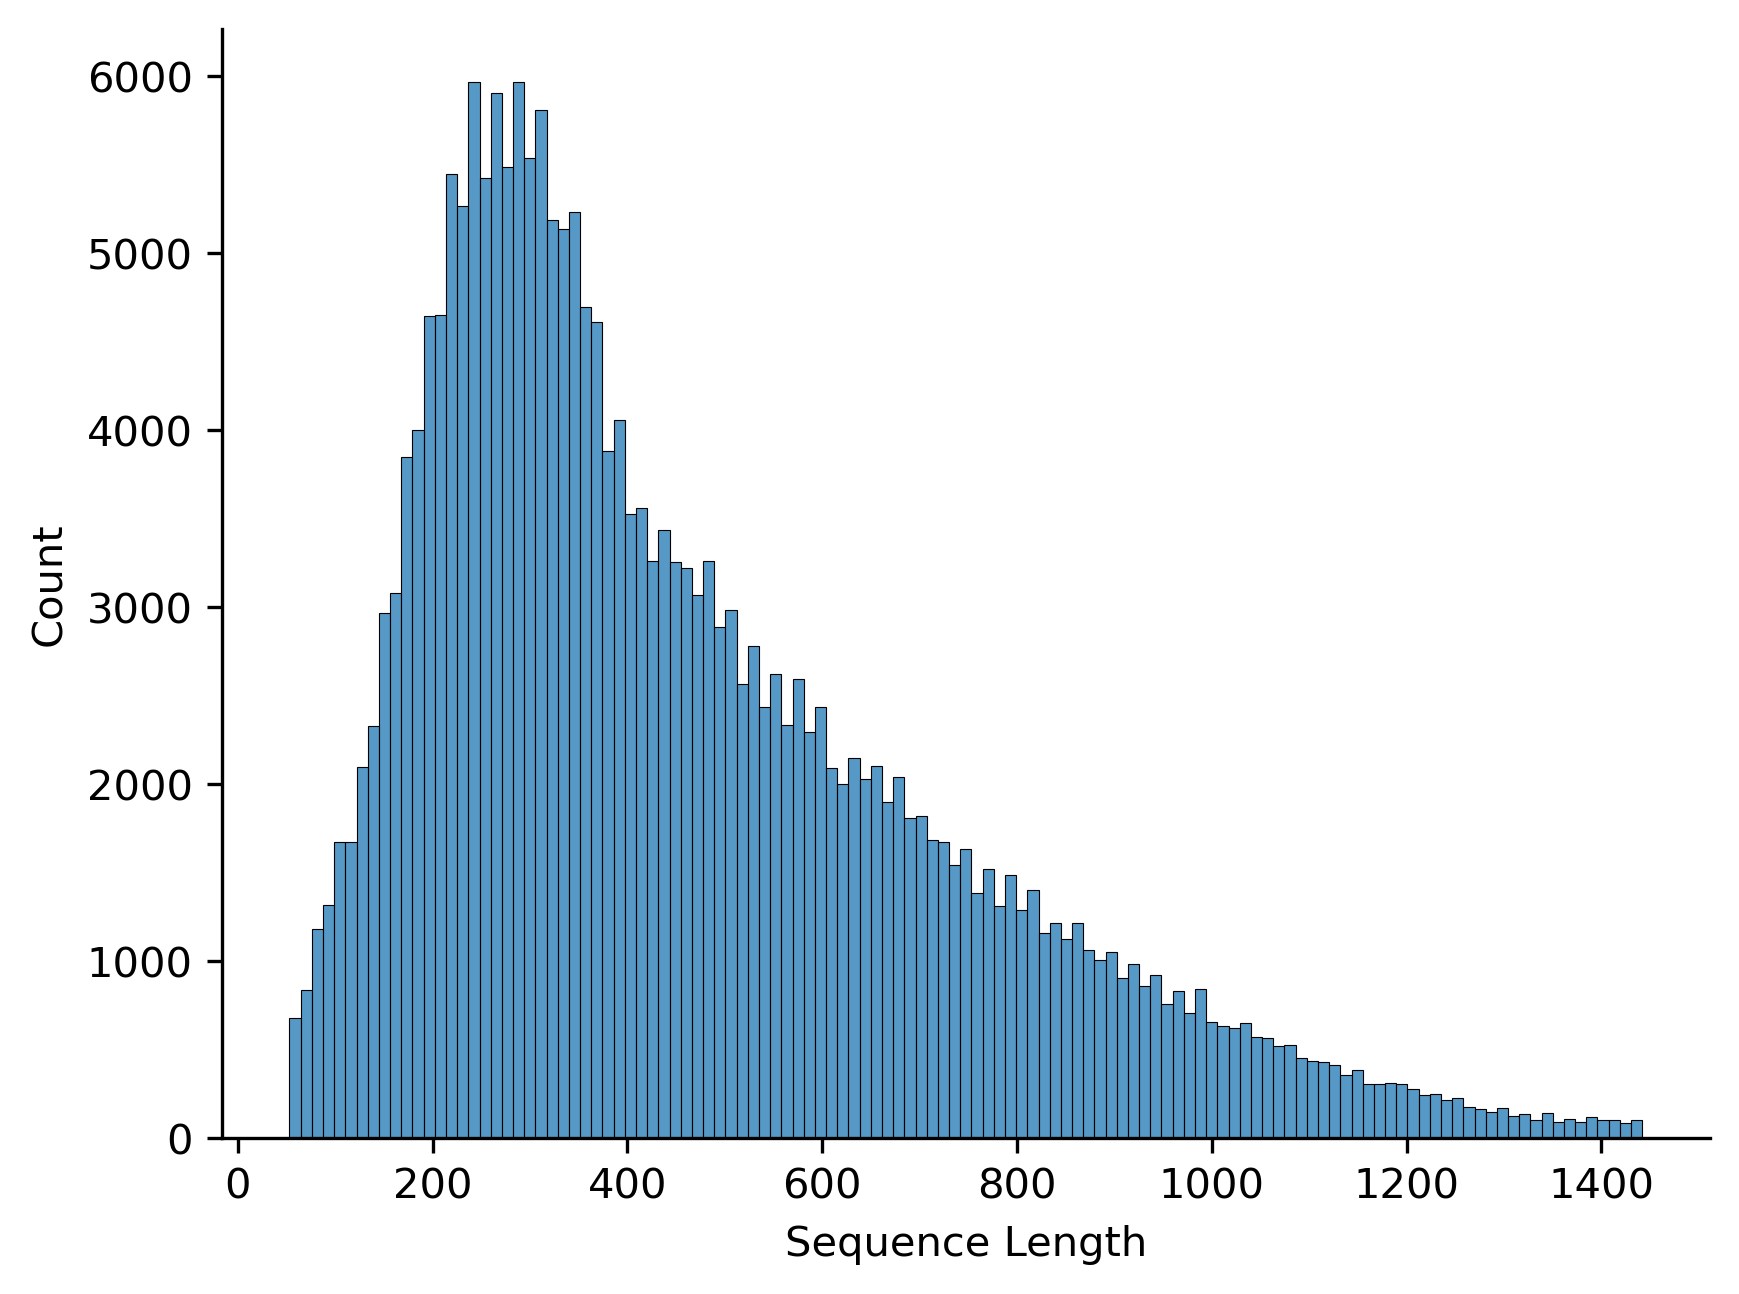

In [29]:
plt.figure(dpi = 300)
sns.histplot(df["seq"].str.len())
sns.despine()
plt.xlabel("Sequence Length")